# 03 — XGBoost ayarı ve karşılaştırma modelleri

**Amaç:** Ana model olan XGBoost'un hiperparametrelerini ayarlamak, sınıf dengesizliği için
`scale_pos_weight` kararını vermek ve Logistic Regression, LightGBM, Random Forest ile karşılaştırmak.

Bu notebook'ta da **test setine dokunulmaz**. Arama eğitim setinde 5 katlı CV ile, model seçimi
doğrulama setiyle yapılır. Seçilen hiperparametreler `ml/reports/phase1/best_params.json` dosyasına
yazılır; `04_evaluation_explainability.ipynb` oradan okur.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

from loan_ml.data import ML_ROOT, RANDOM_STATE, clean, load_raw, split, xy
from loan_ml.evaluation import best_f1_threshold, evaluate, metrics_row
from loan_ml.features import build_pipeline

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 110

REPORT_DIR = ML_ROOT / "reports" / "phase1"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

C:\Users\semih\PythonProjects\loan-approval\ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
splits = split(clean(load_raw()))
X_train, y_train = xy(splits.train)
X_val, y_val = xy(splits.val)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
neg_pos_ratio = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Eğitim: {len(X_train):,} · Doğrulama: {len(X_val):,} · negatif/pozitif oranı: {neg_pos_ratio:.2f}")


def cv_auc(model) -> float:
    return float(cross_val_score(build_pipeline(model), X_train, y_train, cv=cv, scoring="roc_auc").mean())

Eğitim: 31,493 · Doğrulama: 6,748 · negatif/pozitif oranı: 3.50


## 1. XGBoost — Optuna ile arama

5 katlı katmanlı CV, hedef metrik ROC-AUC (TPE örnekleyici, 40 deneme).

In [3]:
XGB_FIXED = {"tree_method": "hist", "random_state": RANDOM_STATE, "n_jobs": 4, "eval_metric": "logloss"}


def xgb_objective(trial: optuna.Trial) -> float:
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 150, 900, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 10.0),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 5.0, log=True),
    }
    return cv_auc(XGBClassifier(**params, **XGB_FIXED))


xgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
xgb_study.optimize(xgb_objective, n_trials=40)
xgb_params = xgb_study.best_params
print(f"En iyi CV ROC-AUC: {xgb_study.best_value:.5f}")
xgb_params

En iyi CV ROC-AUC: 0.97878


{'n_estimators': 650,
 'learning_rate': 0.12337908048803907,
 'max_depth': 7,
 'min_child_weight': 6.070113699772554,
 'subsample': 0.8908461498260349,
 'colsample_bytree': 0.6238897070497358,
 'gamma': 1.0103335992309197,
 'reg_lambda': 0.47005720045566757,
 'reg_alpha': 0.009269738288123927}

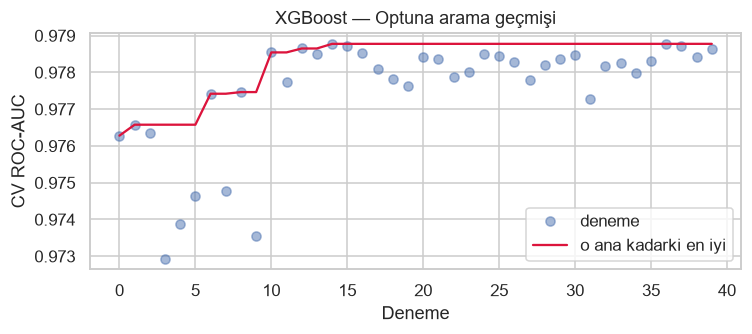

In [4]:
trials = xgb_study.trials_dataframe()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(trials["number"], trials["value"], "o", alpha=0.5, label="deneme")
ax.plot(trials["number"], trials["value"].cummax(), color="crimson", label="o ana kadarki en iyi")
ax.set(title="XGBoost — Optuna arama geçmişi", xlabel="Deneme", ylabel="CV ROC-AUC")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Sınıf dengesizliği: `scale_pos_weight`

Aynı hiperparametrelerle iki model eğitilir; karar doğrulama setindeki **PR-AUC** ve **kalibrasyona
(Brier)** göre verilir.

In [5]:
variants = {}
for label, spw in [("ağırlıksız (scale_pos_weight = 1)", 1.0), (f"ağırlıklı (scale_pos_weight = {neg_pos_ratio:.2f})", neg_pos_ratio)]:
    model = build_pipeline(XGBClassifier(**xgb_params, **XGB_FIXED, scale_pos_weight=spw)).fit(X_train, y_train)
    proba = model.predict_proba(X_val)[:, 1]
    variants[label] = {"spw": spw, "proba": proba, "result": evaluate(splits.val, proba, best_f1_threshold(y_val, proba))}

spw_table = pd.DataFrame([metrics_row(k, v["result"]) for k, v in variants.items()]).set_index("model")
spw_table[["overall_pr_auc", "no_default_pr_auc", "overall_roc_auc", "no_default_roc_auc",
           "overall_brier", "no_default_brier", "overall_f1"]].T

model,ağırlıksız (scale_pos_weight = 1),ağırlıklı (scale_pos_weight = 3.50)
overall_pr_auc,0.9360,0.9345
no_default_pr_auc,0.9360,0.9345
overall_roc_auc,0.9768,0.9763
no_default_roc_auc,0.9325,0.9312
overall_brier,0.0483,0.0547
no_default_brier,0.0986,0.1117
overall_f1,0.8465,0.8407


In [6]:
# Decision rule: prefer the unweighted model unless weighting improves PR-AUC by a meaningful margin
# without hurting calibration. Weighting distorts probabilities, and the UI shows probabilities.
(unw_label, unw), (w_label, w) = variants.items()
pr_gain = w["result"]["no_default"]["pr_auc"] - unw["result"]["no_default"]["pr_auc"]
brier_cost = w["result"]["no_default"]["brier"] - unw["result"]["no_default"]["brier"]
use_weight = pr_gain > 0.002 and brier_cost <= 0
scale_pos_weight = w["spw"] if use_weight else 1.0
print(f"`No` alt grubunda PR-AUC farkı (ağırlıklı − ağırlıksız): {pr_gain:+.4f}")
print(f"`No` alt grubunda Brier farkı  (ağırlıklı − ağırlıksız): {brier_cost:+.4f}  (pozitif = daha kötü)")
print("Karar: scale_pos_weight =", round(scale_pos_weight, 2))

`No` alt grubunda PR-AUC farkı (ağırlıklı − ağırlıksız): -0.0015
`No` alt grubunda Brier farkı  (ağırlıklı − ağırlıksız): +0.0131  (pozitif = daha kötü)
Karar: scale_pos_weight = 1.0


## 3. Karşılaştırma modelleri

### LightGBM (Optuna, 25 deneme)

In [7]:
LGBM_FIXED = {"random_state": RANDOM_STATE, "n_jobs": 4, "verbose": -1}


def lgbm_objective(trial: optuna.Trial) -> float:
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 150, 900, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 96),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
    }
    return cv_auc(LGBMClassifier(**params, **LGBM_FIXED))


lgbm_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
lgbm_study.optimize(lgbm_objective, n_trials=25)
lgbm_params = {**lgbm_study.best_params, "subsample_freq": 1}
print(f"En iyi CV ROC-AUC: {lgbm_study.best_value:.5f}")
lgbm_params

En iyi CV ROC-AUC: 0.97894


{'n_estimators': 500,
 'learning_rate': 0.028146584296848017,
 'num_leaves': 87,
 'min_child_samples': 64,
 'subsample': 0.9988557794457933,
 'colsample_bytree': 0.62265157672646,
 'reg_lambda': 3.550803123801335,
 'subsample_freq': 1}

### Random Forest (Optuna, 12 deneme)

In [8]:
RF_FIXED = {"random_state": RANDOM_STATE, "n_jobs": 4}


def rf_objective(trial: optuna.Trial) -> float:
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 500, step=100),
        "max_depth": trial.suggest_int("max_depth", 8, 24),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_float("max_features", 0.3, 0.9),
    }
    return cv_auc(RandomForestClassifier(**params, **RF_FIXED))


rf_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
rf_study.optimize(rf_objective, n_trials=12)
rf_params = rf_study.best_params
print(f"En iyi CV ROC-AUC: {rf_study.best_value:.5f}")
rf_params

En iyi CV ROC-AUC: 0.97481


{'n_estimators': 300,
 'max_depth': 16,
 'min_samples_leaf': 1,
 'max_features': 0.6273941267719517}

### Logistic Regression (baseline)

`02_preprocessing_baseline.ipynb` içindeki aramanın aynısı (ağırlıksız, CV ROC-AUC'ye göre `C`).

In [9]:
lr_scores = {
    c: float(cross_val_score(build_pipeline(LogisticRegression(C=c, max_iter=2000), linear=True),
                             X_train, y_train, cv=cv, scoring="roc_auc").mean())
    for c in [0.01, 0.1, 1.0, 10.0]
}
lr_params = {"C": max(lr_scores, key=lr_scores.get)}
print("CV ROC-AUC:", {k: round(v, 5) for k, v in lr_scores.items()}, "→", lr_params)

CV ROC-AUC: {0.01: 0.95497, 0.1: 0.95554, 1.0: 0.95559, 10.0: 0.95559} → {'C': 10.0}


## 4. Doğrulama setinde karşılaştırma

Her model eğitim setinin tamamında eğitilir; eşik her model için doğrulama setinde F1'i en yükselten
değerdir.

In [10]:
candidates = {
    "Logistic Regression": build_pipeline(LogisticRegression(**lr_params, max_iter=2000), linear=True),
    "Random Forest": build_pipeline(RandomForestClassifier(**rf_params, **RF_FIXED)),
    "LightGBM": build_pipeline(LGBMClassifier(**lgbm_params, **LGBM_FIXED)),
    "XGBoost": build_pipeline(XGBClassifier(**xgb_params, **XGB_FIXED, scale_pos_weight=scale_pos_weight)),
}
cv_scores = {
    "Logistic Regression": lr_scores[lr_params["C"]],
    "Random Forest": rf_study.best_value,
    "LightGBM": lgbm_study.best_value,
    "XGBoost": xgb_study.best_value,
}

rows, thresholds = [], {}
for name, model in candidates.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_val)[:, 1]
    thresholds[name] = best_f1_threshold(y_val, proba)
    row = metrics_row(name, evaluate(splits.val, proba, thresholds[name]))
    row["cv_roc_auc"] = cv_scores[name]
    row["threshold"] = thresholds[name]
    rows.append(row)

val_table = pd.DataFrame(rows).set_index("model")
val_table.to_csv(REPORT_DIR / "validation_comparison.csv")
val_table[["cv_roc_auc", "overall_roc_auc", "overall_pr_auc", "overall_f1", "overall_brier", "threshold"]]

,cv_roc_auc,overall_roc_auc,overall_pr_auc,overall_f1,overall_brier,threshold
model,,,,,,
Logistic Regression,0.9556,0.9547,0.8566,0.7733,0.0713,0.4500
Random Forest,0.9748,0.9738,0.9278,0.8381,0.0516,0.3500
LightGBM,0.9789,0.9768,0.9360,0.8478,0.0485,0.4389
XGBoost,0.9788,0.9768,0.9360,0.8465,0.0483,0.4609


**`No` alt grubu** (geçmiş temerrüt kaydı olmayanlar) — modelin gerçek ayırt etme gücü:

In [11]:
val_table[["no_default_roc_auc", "no_default_pr_auc", "no_default_f1", "no_default_precision",
           "no_default_recall", "no_default_brier"]]

,no_default_roc_auc,no_default_pr_auc,no_default_f1,no_default_precision,no_default_recall,no_default_brier
model,,,,,,
Logistic Regression,0.8683,0.8566,0.7733,0.7561,0.7913,0.1456
Random Forest,0.9240,0.9278,0.8381,0.8259,0.8507,0.1054
LightGBM,0.9325,0.9360,0.8478,0.8707,0.8260,0.0990
XGBoost,0.9325,0.9360,0.8465,0.8748,0.8200,0.0986


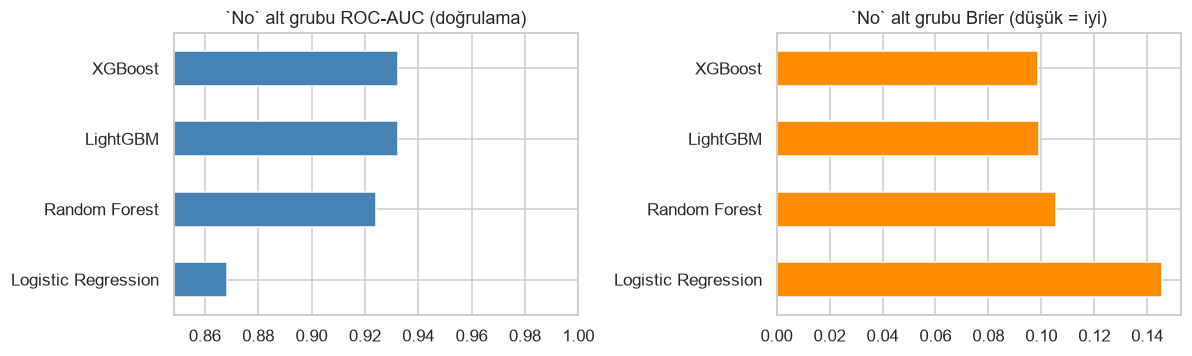

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
val_table["no_default_roc_auc"].plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="`No` alt grubu ROC-AUC (doğrulama)", ylabel="",
            xlim=(val_table["no_default_roc_auc"].min() - 0.02, 1))
val_table["no_default_brier"].plot.barh(ax=axes[1], color="darkorange")
axes[1].set(title="`No` alt grubu Brier (düşük = iyi)", ylabel="")
plt.tight_layout()
plt.show()

## 5. Seçilen yapılandırmanın kaydı

In [13]:
best_params = {
    "random_state": RANDOM_STATE,
    "xgboost": {**xgb_params, "scale_pos_weight": scale_pos_weight},
    "lightgbm": lgbm_params,
    "random_forest": rf_params,
    "logistic_regression": lr_params,
    "cv_roc_auc": cv_scores,
    "validation_f1_thresholds": thresholds,
}
(REPORT_DIR / "best_params.json").write_text(json.dumps(best_params, indent=2), encoding="utf-8")
print(json.dumps(best_params["xgboost"], indent=2))

{
  "n_estimators": 650,
  "learning_rate": 0.12337908048803907,
  "max_depth": 7,
  "min_child_weight": 6.070113699772554,
  "subsample": 0.8908461498260349,
  "colsample_bytree": 0.6238897070497358,
  "gamma": 1.0103335992309197,
  "reg_lambda": 0.47005720045566757,
  "reg_alpha": 0.009269738288123927,
  "scale_pos_weight": 1.0
}
